# 03 · The toric code: the simplest Z₂ spin liquid

$$H = -J_e\sum_s A_s - J_m\sum_p B_p,\qquad A_s=\prod_{e\in s}\sigma^x_e,\quad B_p=\prod_{e\in p}\sigma^z_e$$

**What you will learn**
1. ED: 4-fold topological degeneracy and its labelling by Wilson loops.
2. Anyons: create $e$ and $m$ pairs with strings and measure their energies.
3. Topological entanglement entropy $\gamma=\ln 2$ (Kitaev-Preskill and Levin-Wen) on hundreds of qubits with the stabilizer formalism.
4. A magnetic field drives a confinement transition, and the topological degeneracy is lost.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import qslab
from qslab import models, ED, sigma
from qslab.stabilizer import (toric_code_ground_state, kitaev_preskill_regions,
                              levin_wen_regions, topological_entropy)

## 1. ED on an L = 3 torus (18 qubits)

In [2]:
tc, H = models.toric_code(3)
print(tc)
ed = ED(H, tc.N)
w, v = ed.diagonalize(k=8)
print("lowest levels:", np.round(w, 6))
print("multiplets:", ed.multiplets())

<ToricCodeLattice 3x3: 18 qubits>


lowest levels: [-18. -18. -18. -18. -14. -14. -14. -14.]
multiplets: [(np.float64(-18.000000000000004), 4), (np.float64(-14.000000000000007), 4)]


The four ground states are distinguished by non-contractible Wilson loops $Z_1, Z_2$ (strings of $\sigma^z$ around the torus):

In [3]:
for E, (z1, z2) in ed.symmetry_eigenvalues([tc.logical_Z(0), tc.logical_Z(1)])[:4]:
    print(f"E = {E:.3f}   Z1 = {z1:+.0f}   Z2 = {z2:+.0f}")

E = -18.000   Z1 = -1   Z2 = -1
E = -18.000   Z1 = +1   Z2 = +1
E = -18.000   Z1 = -1   Z2 = +1
E = -18.000   Z1 = +1   Z2 = -1


## 2. Anyons from string operators
A $\sigma^z$ on one edge violates the two stars at its ends, which creates an $e$ pair costing $4J_e$. A $\sigma^x$ string creates $m$ pairs at its plaquette end points.

In [4]:
psi0 = v[:, 0]
e_pair = ed.apply(sigma(tc.h(0, 0), "z"), psi0)
m_pair = ed.apply(sigma(tc.h(0, 0), "x"), psi0)
print("E(e pair) - E0 =", ed.energy(e_pair) - w[0])
print("E(m pair) - E0 =", ed.energy(m_pair) - w[0])
# stretching the string costs nothing more: anyons are deconfined
long_e = ed.apply(sigma(tc.h(0, 0), "z") * sigma(tc.h(1, 0), "z"), psi0)
print("E(longer e string) - E0 =", ed.energy(long_e) - w[0])

E(e pair) - E0 = 4.0000000000000036
E(m pair) - E0 = 4.000000000000002
E(longer e string) - E0 = 4.000000000000002


## 3. Topological entanglement entropy with stabilizers
A stabilizer state with generators $G$ has entropy $S_A/\ln2 = \mathrm{rank}_{GF(2)}(G|_A) - |A|$, which is exact for any size.

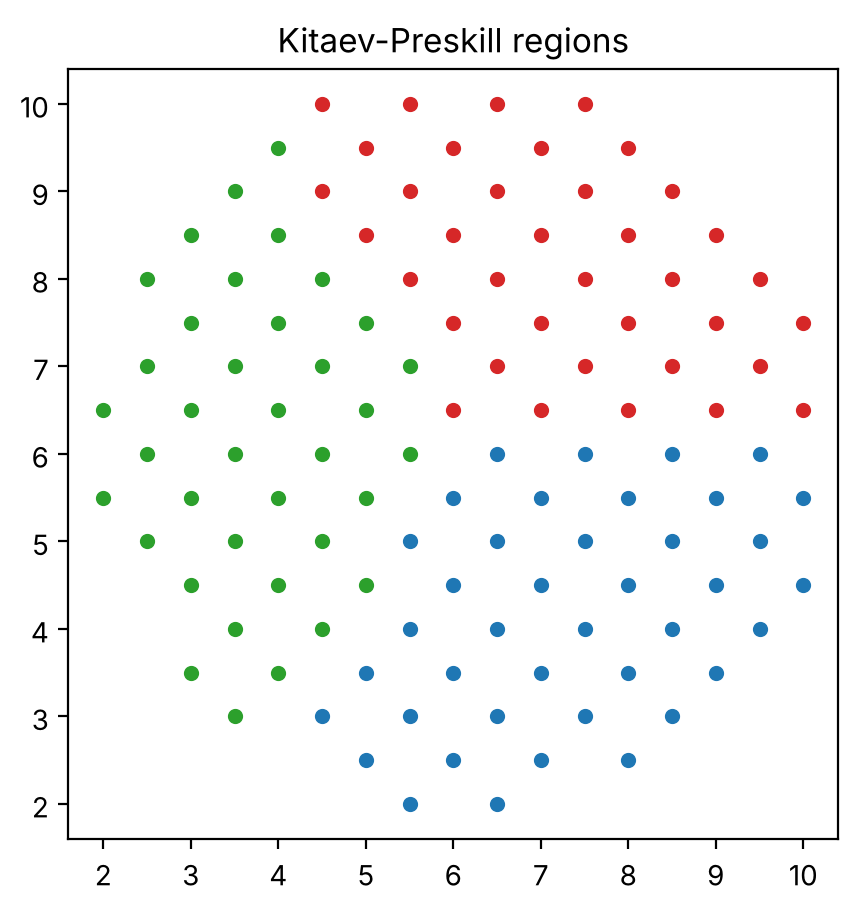

gamma (KP) = 0.6931471805599453   ln 2 = 0.6931471805599453


gamma (LW) = 0.6931471805599453


In [5]:
tc12, st = toric_code_ground_state(12)
A, B, C = kitaev_preskill_regions(tc12)
fig, ax = plt.subplots(figsize=(5, 5))
for reg, col in zip((A, B, C), ("tab:red", "tab:green", "tab:blue")):
    P = np.array([tc12.edge_midpoint(e) for e in reg]); ax.scatter(*P.T, c=col, s=20)
ax.set_aspect("equal"); ax.set_title("Kitaev-Preskill regions"); plt.show()
print("gamma (KP) =", topological_entropy(st, A, B, C), "  ln 2 =", np.log(2))
print("gamma (LW) =", topological_entropy(st, *levin_wen_regions(tc12), scheme="LW"))

**Area law:** $S_A = \alpha|\partial A| - \gamma$. Fitting disks of increasing radius gives the intercept $-\gamma$:

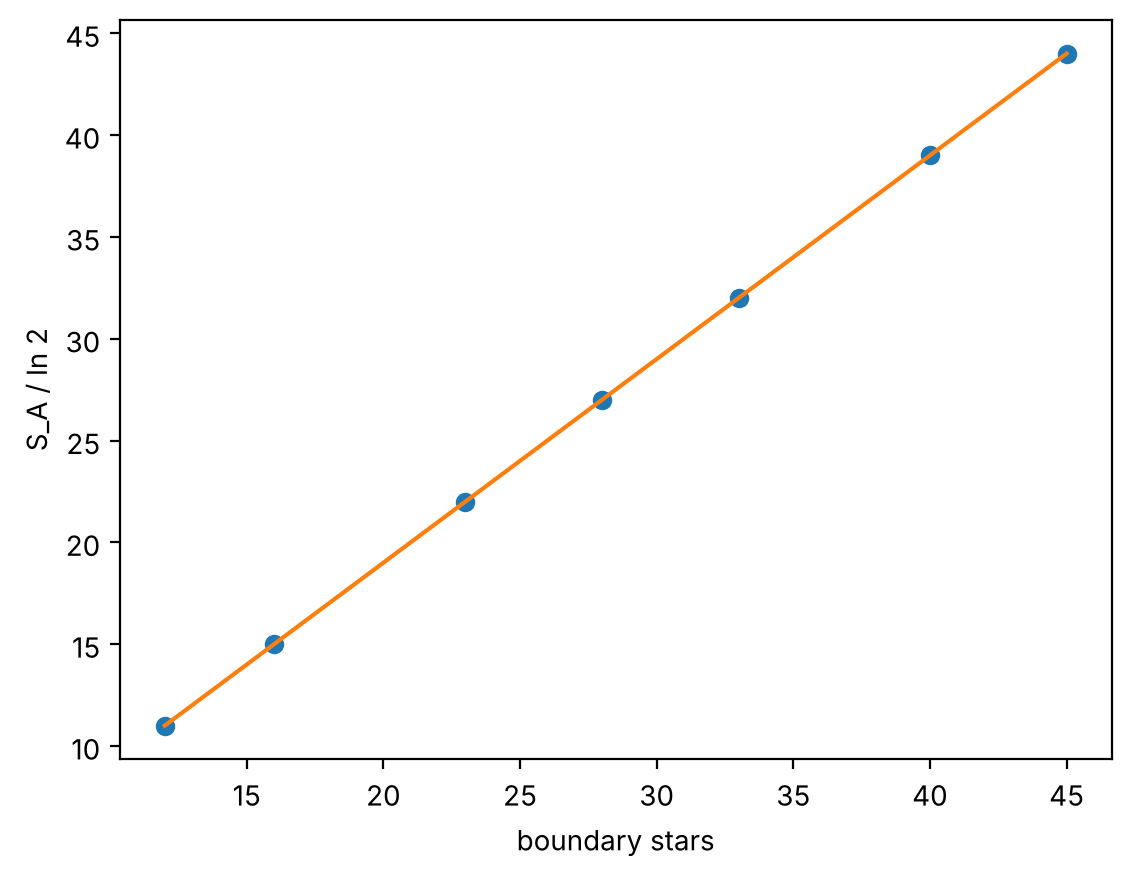

fit: S = 1.000 L_boundary -1.000   -> gamma/ln2 = 1.000


In [6]:
tcL, stL = toric_code_ground_state(24)
c0 = np.array([12.13, 12.13]); Rs = np.arange(2, 9); S, perim = [], []
for R in Rs:
    reg = [e for e in range(tcL.N) if np.linalg.norm(tcL.edge_midpoint(e) - c0) < R]
    S.append(stL.entropy(reg))
    # boundary = number of stars cut by the region (shared between A and its complement)
    inside = set(reg)
    perim.append(sum(1 for s in tcL.stars() if 0 < len(inside & set(s)) < 4))
S, perim = np.array(S), np.array(perim)
fit = np.polyfit(perim, S, 1)
plt.plot(perim, S, "o"); plt.plot(perim, np.polyval(fit, perim)); plt.xlabel("boundary stars"); plt.ylabel("S_A / ln 2"); plt.show()
print("fit: S = %.3f L_boundary %+.3f   -> gamma/ln2 = %.3f" % (fit[0], fit[1], -fit[1]))

## 4. Field-induced confinement (ED)
A field $h_z$ gives the $e$ anyons dynamics. The four ground states split by an amount $\sim e^{-L/\xi}$ in the topological phase, and the splitting becomes large once the anyons condense (around $h\approx0.33$ in the thermodynamic limit). This is a finite-size crossover on L = 3.

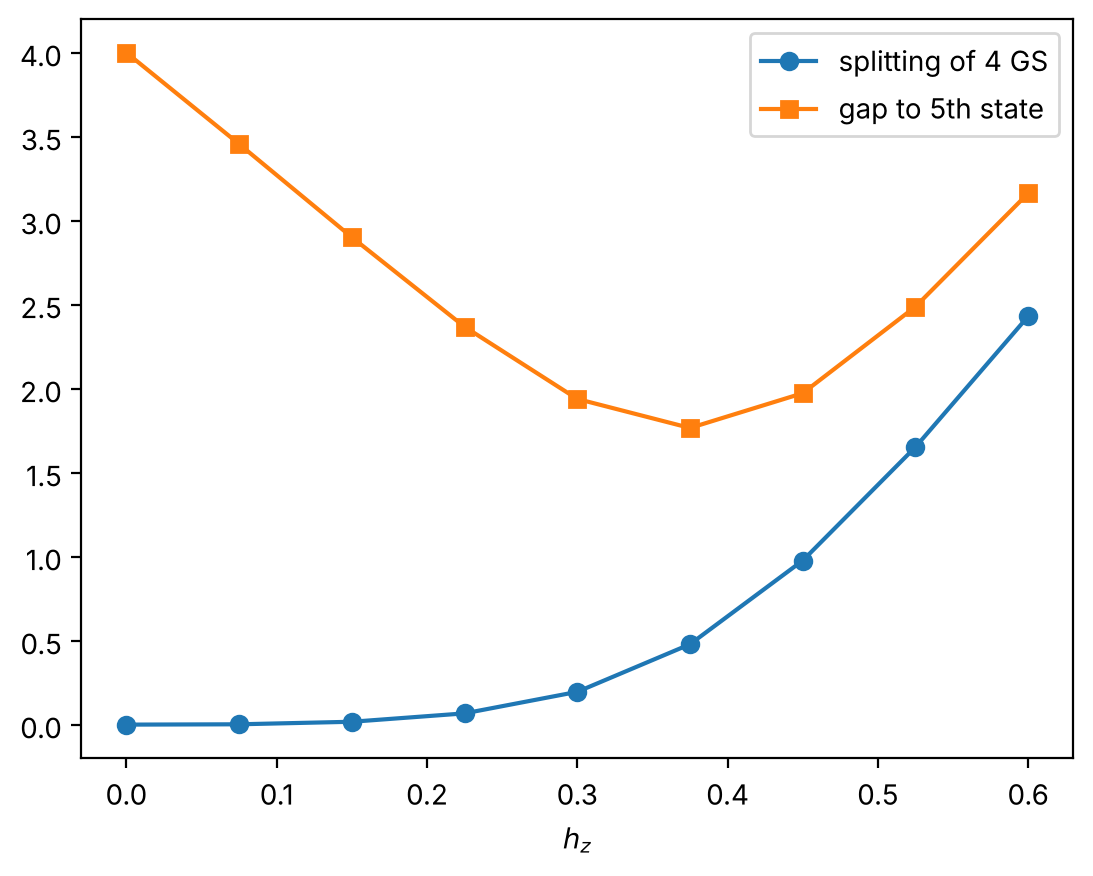

In [7]:
hs = np.linspace(0, 0.6, 9); split, gap = [], []
for h in hs:
    tc, H = models.toric_code(3, hz=h)
    w, _ = ED(H, tc.N).diagonalize(k=6)
    split.append(w[3] - w[0]); gap.append(w[4] - w[0])
plt.plot(hs, split, "o-", label="splitting of 4 GS"); plt.plot(hs, gap, "s-", label="gap to 5th state")
plt.xlabel("$h_z$"); plt.legend(); plt.show()

## Quiz

In [8]:
from qslab import quiz
quiz.show("toric_code")

=== Toric code / Z2 topological order ===
H = -Je sum_s A_s - Jm sum_p B_p on an L x L torus.

Q1. [numeric] Ground-state energy of the L = 3 toric code (Je = Jm = 1)?
    -> numeric answer (tolerance 1e-06)

Q2. [numeric] Ground-state degeneracy on the torus?
    -> numeric answer (tolerance 0)

Q3. [numeric] Ground-state degeneracy on a genus-2 surface?
    -> numeric answer (tolerance 0)

Q4. [numeric] Energy of the lowest excitation (Je = Jm = 1)?
    -> numeric answer (tolerance 1e-06)

Q5. [numeric] Topological entanglement entropy gamma (in nats)?
    -> numeric answer (tolerance 0.001)

Q6. [mcq] Why does the Kitaev-Preskill combination S_A+S_B+S_C-S_AB-S_BC-S_CA+S_ABC isolate -gamma?
    (a) It vanishes for all states
    (b) It is the mutual information
    (c) Boundary (area-law) and corner contributions cancel by inclusion-exclusion
    (d) It counts Bell pairs

Q7. [mcq] Which is the e-particle (charge) of the toric code?
    (a) a magnon
    (b) violated star A_s = -1
   